# Movies & Me — Phase 2 : baseline content-based par genres

**Objectif :** recommander des films à partir de favoris MovieLens avec une première approche interprétable : **genres → TF-IDF → profil moyen → similarité cosinus → Top-N**.

Les IDs utilisés dans cette phase sont les **`movieId` MovieLens**, pas les `tmdbId`. Le catalogue fourni en phase 1 sert à construire les features ; les notes et les tags ne servent pas au classement de cette baseline.

Ce notebook présente les choix, inspecte les features, exécute des exemples et vérifie le contrat. La logique réutilisable est dans `src/models/content_based.py`, après validation du prototype. Le notebook appelle ce même code ; les tests le vérifient indépendamment.

## 1. Chargement et configuration

Les CSV locaux sont utilisés sans modification. Aucune clé API ni requête réseau n'est nécessaire. Depuis la racine du dépôt, installer `requirements.txt`, puis exécuter toutes les cellules dans l'ordre.

In [1]:
from pathlib import Path
import json
import platform
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import Markdown, display

PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "data/raw/movies.csv").is_file()
    and (p / "src/data/exploration.py").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Ouvrir ce notebook depuis le dépôt movies-and-me-recommender.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.data.exploration import load_movielens

movies = load_movielens(PROJECT_ROOT / "data/raw")["movies"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print(f"Python {platform.python_version()} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")
print(f"Catalogue : {len(movies):,} films")
display(movies.head())

Python 3.12.7 | pandas 3.0.6 | scikit-learn 1.9.1
Catalogue : 9,742 films


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


## 2. Genres et vectorisation TF-IDF

- Chaque genre est un token entier : `Sci-Fi` et `Film-Noir` conservent leurs tirets.
- `(no genres listed)` et les valeurs vides ne créent pas de feature.
- `IMAX` est exclu par défaut car c'est un format de projection. Une variante le conservant sera inspectée ci-dessous ; ce choix n'est pas présenté comme un gain prédictif.
- Les genres rares ont un poids IDF plus élevé. Les vecteurs des films sont normalisés en L2.
- Les films sans genre utilisable restent dans le catalogue avec un vecteur nul.

In [2]:
from src.models.content_based import ContentBasedRecommender, tokenize_genres

In [3]:
recommender = ContentBasedRecommender(movies)
features = recommender.feature_matrix
zero_vector_mask = np.asarray(features.getnnz(axis=1) == 0).ravel()
feature_summary = pd.DataFrame({
    "genre": recommender.feature_names,
    "idf": recommender.vectorizer.idf_,
    "num_movies": np.asarray((features > 0).sum(axis=0)).ravel(),
}).sort_values("idf", ascending=False)
print(f"Matrice sparse : {features.shape[0]} films × {features.shape[1]} genres")
print(f"Films sans genre utilisable : {int(zero_vector_mask.sum())}")
print("Tokens d'exemple :", tokenize_genres("Sci-Fi|Film-Noir|IMAX|(no genres listed)"))
display(feature_summary)
display(recommender.movies.loc[zero_vector_mask].head(10))

assert features.shape[0] == len(movies)
assert np.isfinite(features.data).all()
assert "Sci-Fi" in recommender.feature_names and "Film-Noir" in recommender.feature_names
assert "IMAX" not in recommender.feature_names and "(no genres listed)" not in recommender.feature_names

Matrice sparse : 9742 films × 18 genres
Films sans genre utilisable : 34
Tokens d'exemple : ['Film-Noir', 'Sci-Fi']


,genre,idf,num_movies
9,Film-Noir,5.706968,87
17,Western,5.060340,167
11,Musical,4.370174,334
16,War,4.236269,382
6,Documentary,4.095259,440
12,Mystery,3.831675,573
2,Animation,3.767572,611
3,Children,3.684517,664
8,Fantasy,3.525010,779
10,Horror,3.297773,978


,movieId,title,genres
8517,114335,La cravate (1957),(no genres listed)
8684,122888,Ben-hur (2016),(no genres listed)
8687,122896,Pirates of the Caribbean: Dead Men Tell No Tal...,(no genres listed)
8782,129250,Superfast! (2015),(no genres listed)
8836,132084,Let It Be Me (1995),(no genres listed)
8902,134861,Trevor Noah: African American (2013),(no genres listed)
9033,141131,Guardians (2016),(no genres listed)
9053,141866,Green Room (2015),(no genres listed)
9070,142456,The Brand New Testament (2015),(no genres listed)
9091,143410,Hyena Road,(no genres listed)


## 3. Profil utilisateur et similarité

Pour des favoris distincts, on calcule la moyenne de leurs vecteurs TF-IDF, puis la similarité cosinus entre ce profil et chaque film du catalogue. Les favoris sont exclus des candidats. Aucun tableau dense de similarités film × film n'est construit.

On retourne jusqu'à `n` films ayant un score strictement positif, avec un tri déterministe : score décroissant, puis `movieId` croissant en cas d'ex æquo. Les scores sont entre 0 et 1 ; ils représentent une ressemblance entre genres, pas une probabilité d'aimer le film ni une note prédite.

**Favoris : Star Wars IV, Star Wars V, Matrix**

,movieId,title,genres
224,260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi
898,1196,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Sci-Fi
1939,2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller


,Action,Adventure,Animation,Children,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
title,,,,,,,,,,,,,,,,,,
Star Wars: Episode IV - A New Hope (1977),0.511908,0.582675,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.63122,0.000000,0.0,0.0
Star Wars: Episode V - The Empire Strikes Back (1980),0.511908,0.582675,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.63122,0.000000,0.0,0.0
"Matrix, The (1999)",0.534972,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.65966,0.527877,0.0,0.0


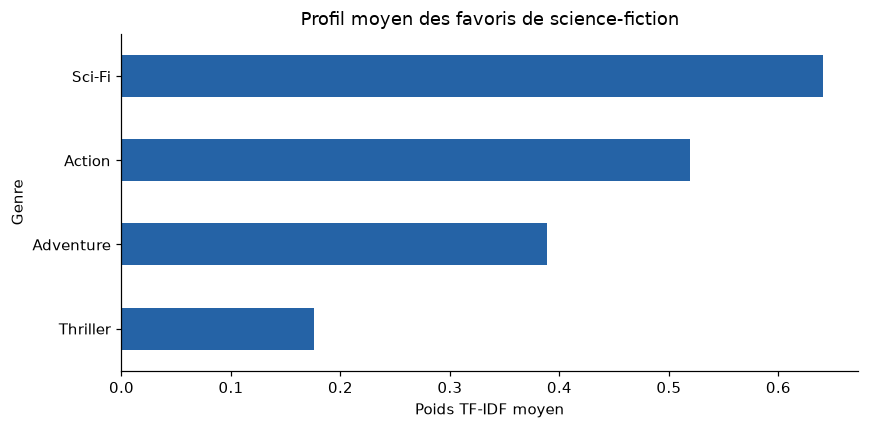

In [4]:
science_fiction_favorites = [260, 1196, 2571]
display(Markdown("**Favoris : Star Wars IV, Star Wars V, Matrix**"))
favorite_rows = recommender.movies.loc[recommender.movies["movieId"].isin(science_fiction_favorites)]
display(favorite_rows)
positions = favorite_rows.index.to_list()
favorite_vectors = features[positions].toarray()
display(pd.DataFrame(favorite_vectors, index=favorite_rows["title"], columns=recommender.feature_names))
profile_weights = pd.Series(favorite_vectors.mean(axis=0), index=recommender.feature_names)
profile_weights = profile_weights.loc[profile_weights.gt(0)].sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
profile_weights.plot.barh(ax=ax, color="#2563a6")
ax.set(title="Profil moyen des favoris de science-fiction", xlabel="Poids TF-IDF moyen", ylabel="Genre")
fig.tight_layout()
plt.show()

In [5]:
science_fiction_recommendations = recommender.recommend(science_fiction_favorites, n=10)
display(Markdown("**Top 10 — profil science-fiction**"))
display(science_fiction_recommendations)

**Top 10 — profil science-fiction**

,movieId,title,genres,score
0,208,Waterworld (1995),Action|Adventure|Sci-Fi,0.965681
1,316,Stargate (1994),Action|Adventure|Sci-Fi,0.965681
2,442,Demolition Man (1993),Action|Adventure|Sci-Fi,0.965681
3,1210,Star Wars: Episode VI - Return of the Jedi (1983),Action|Adventure|Sci-Fi,0.965681
4,1375,Star Trek III: The Search for Spock (1984),Action|Adventure|Sci-Fi,0.965681
5,1831,Lost in Space (1998),Action|Adventure|Sci-Fi,0.965681
6,2094,"Rocketeer, The (1991)",Action|Adventure|Sci-Fi,0.965681
7,2105,Tron (1982),Action|Adventure|Sci-Fi,0.965681
8,2275,Six-String Samurai (1998),Action|Adventure|Sci-Fi,0.965681
9,2528,Logan's Run (1976),Action|Adventure|Sci-Fi,0.965681


In [6]:
animation_favorites = [1, 6377, 8961]
display(Markdown("**Favoris : Toy Story, Finding Nemo, Incredibles**"))
display(recommender.movies.loc[recommender.movies["movieId"].isin(animation_favorites)])
animation_recommendations = recommender.recommend(animation_favorites, n=10)
display(Markdown("**Top 10 — profil animation**"))
display(animation_recommendations)

**Favoris : Toy Story, Finding Nemo, Incredibles**

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
4360,6377,Finding Nemo (2003),Adventure|Animation|Children|Comedy
5374,8961,"Incredibles, The (2004)",Action|Adventure|Animation|Children|Comedy


**Top 10 — profil animation**

,movieId,title,genres,score
0,2141,"American Tail, An (1986)",Adventure|Animation|Children|Comedy,0.976454
1,2355,"Bug's Life, A (1998)",Adventure|Animation|Children|Comedy,0.976454
2,4990,Jimmy Neutron: Boy Genius (2001),Adventure|Animation|Children|Comedy,0.976454
3,5218,Ice Age (2002),Adventure|Animation|Children|Comedy,0.976454
4,5448,Hey Arnold! The Movie (2002),Adventure|Animation|Children|Comedy,0.976454
5,8974,"SpongeBob SquarePants Movie, The (2004)",Adventure|Animation|Children|Comedy,0.976454
6,27619,"Lion King 1½, The (2004)",Adventure|Animation|Children|Comedy,0.976454
7,33615,Madagascar (2005),Adventure|Animation|Children|Comedy,0.976454
8,38038,Wallace & Gromit in The Curse of the Were-Rabb...,Adventure|Animation|Children|Comedy,0.976454
9,43869,Curious George (2006),Adventure|Animation|Children|Comedy,0.976454


## 4. Inspection du choix IMAX et des ex æquo

Une variante conserve `IMAX` comme feature. On compare les dimensions et les sorties, sans attribuer de valeur prédictive aux changements. Interstellar (`movieId=109487`, genres `Sci-Fi|IMAX`) illustre directement l'effet de ce choix.

Les genres seuls peuvent attribuer le même score à des films très différents. Le départage par `movieId` facilite la reproduction, mais privilégie arbitrairement les petits IDs ; il ne représente ni qualité ni popularité. Une future évaluation offline sera nécessaire pour comparer les approches.

In [7]:
with_imax = ContentBasedRecommender(movies, include_imax=True)
comparison = pd.DataFrame([
    {"configuration": "IMAX exclu (défaut)", "num_features": len(recommender.feature_names),
     "zero_vectors": int(zero_vector_mask.sum())},
    {"configuration": "IMAX conservé", "num_features": len(with_imax.feature_names),
     "zero_vectors": int((with_imax.feature_matrix.getnnz(axis=1) == 0).sum())},
])
display(comparison)
display(movies.loc[movies["movieId"].eq(109487)])
display(Markdown("**Favori Interstellar : IMAX exclu**"))
display(recommender.recommend([109487], n=5))
display(Markdown("**Favori Interstellar : IMAX conservé**"))
display(with_imax.recommend([109487], n=5))

,configuration,num_features,zero_vectors
0,IMAX exclu (défaut),18,34
1,IMAX conservé,19,34


,movieId,title,genres
8376,109487,Interstellar (2014),Sci-Fi|IMAX


**Favori Interstellar : IMAX exclu**

,movieId,title,genres,score
0,2311,2010: The Year We Make Contact (1984),Sci-Fi,1.0
1,2526,Meteor (1979),Sci-Fi,1.0
2,2661,It Came from Outer Space (1953),Sci-Fi,1.0
3,2665,Earth vs. the Flying Saucers (1956),Sci-Fi,1.0
4,2698,Zone 39 (1997),Sci-Fi,1.0


**Favori Interstellar : IMAX conservé**

,movieId,title,genres,score
0,97752,Cloud Atlas (2012),Drama|Sci-Fi|IMAX,0.958772
1,110730,Transcendence (2014),Drama|Sci-Fi|IMAX,0.958772
2,89470,Contagion (2011),Sci-Fi|Thriller|IMAX,0.917532
3,104841,Gravity (2013),Action|Sci-Fi|IMAX,0.915575
4,110553,The Amazing Spider-Man 2 (2014),Action|Sci-Fi|IMAX,0.915575


## 5. Comportements explicites et validation

- Favoris vides, IDs inconnus ou profil sans genre utilisable : `ValueError` explicite.
- Un favori sans genre n'ajoute pas de signal ; avec d'autres favoris utilisables, le profil reste calculable.
- Favoris répétés : déduplication pour conserver un poids égal par film distinct.
- Si moins de `n` candidats ont un score positif, le résultat est plus court. Aucun film sans ressemblance n'est ajouté pour remplir la liste.
- Aucun candidat restant : tableau vide avec les mêmes colonnes.

Les contrôles ci-dessous valident le fonctionnement du prototype. Ils ne calculent ni Recall@K ni NDCG@K : ces métriques appartiennent à la phase d'évaluation.

In [8]:
for favorites, recommendations in [
    (science_fiction_favorites, science_fiction_recommendations),
    (animation_favorites, animation_recommendations),
]:
    assert len(recommendations) == 10
    assert recommendations["movieId"].is_unique
    assert not recommendations["movieId"].isin(favorites).any()
    assert recommendations["score"].between(0, 1).all()
    assert recommendations["score"].gt(0).all()
    assert recommendations["score"].is_monotonic_decreasing
    pd.testing.assert_frame_equal(recommendations, recommender.recommend(favorites[::-1], n=10))
    pd.testing.assert_frame_equal(recommendations, recommender.recommend(favorites + [favorites[0]], n=10))
print("Deux profils validés : 10 films distincts, favoris exclus, scores bornés et ordre reproductible.")

no_genre_id = int(recommender.movies.loc[zero_vector_mask, "movieId"].iloc[0])
for label, favorites in [("Favoris vides", []), ("ID inconnu", [987654321]), ("Profil sans genre", [no_genre_id])]:
    try:
        recommender.recommend(favorites)
    except ValueError as error:
        print(f"{label} → {error}")
    else:
        raise AssertionError(f"Une erreur explicite était attendue : {label}")

Deux profils validés : 10 films distincts, favoris exclus, scores bornés et ordre reproductible.
Favoris vides → At least one favorite movieId is required.
ID inconnu → Unknown MovieLens movieId values: [987654321]
Profil sans genre → Favorites have no usable genres; cannot build a profile.


## 6. Conclusion

La première baseline fonctionne à partir d'une liste de favoris MovieLens. Elle utilise seulement les genres, construit un profil moyen et exclut les favoris de ses recommandations. Les deux exemples produisent dix résultats distincts et reproductibles.

**Limites :** représentation grossière, nombreux ex æquo, catalogue historique et absence de mesure de qualité prédictive. La similarité observée ne démontre pas une performance de recommandation.

**Prochaine étape recommandée : phase 3**, un composant de conversion MovieLens ↔ TMDB avec gestion des absences et de la collision repérée en phase 1. Cette phase reste à réaliser.

In [9]:
summary = {
    "num_movies": len(recommender.movies),
    "num_features": len(recommender.feature_names),
    "num_zero_vectors": int(zero_vector_mask.sum()),
    "num_example_profiles_validated": 2,
    "num_recommendations_per_example": len(science_fiction_recommendations),
    "favorites_excluded": not science_fiction_recommendations["movieId"].isin(science_fiction_favorites).any(),
    "unique_recommendations": science_fiction_recommendations["movieId"].is_unique,
}
print(json.dumps(summary, indent=4, default=bool))

{
    "num_movies": 9742,
    "num_features": 18,
    "num_zero_vectors": 34,
    "num_example_profiles_validated": 2,
    "num_recommendations_per_example": 10,
    "favorites_excluded": true,
    "unique_recommendations": true
}
